In [6]:
%pip install matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 335.3 kB/s  0:00:27m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 803.6 kB/s  0:00:04 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [seaborn]m6/7 [seaborn]ib]
Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/olympics_08_medalists.csv")
df.head()

Matplotlib is building the font cache; this may take a moment.


,medalist_name,male_archery,female_archery,male_athletics,female_athletics,male_badminton,female_badminton,male_baseball,male_basketball,female_basketball,...,female_beach volleyball,male_volleyball,female_volleyball,male_water polo,female_water polo,male_weightlifting,female_weightlifting,male_freestyle wrestling,female_freestyle wrestling,male_greco-roman wrestling
0,Aaron Armstrong,NaN,NaN,gold,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Aaron Peirsol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Abdullo Tangriev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Abeer Abdelrahman,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,bronze,NaN,NaN,NaN
4,Abhinav,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df_long = df.melt(id_vars="medalist_name", var_name = "event", value_name = "medal")
df_long.head()

,medalist_name,event,medal
0,Aaron Armstrong,male_archery,NaN
1,Aaron Peirsol,male_archery,NaN
2,Abdullo Tangriev,male_archery,NaN
3,Abeer Abdelrahman,male_archery,NaN
4,Abhinav,male_archery,NaN


In [14]:
df_long = df_long.dropna(subset=["medal"])
print(df_long.shape)
df_long.head()

(1875, 3)


,medalist_name,event,medal
177,Bair Badënov,male_archery,bronze
676,Ilario Di Buò,male_archery,silver
682,Im Dong-hyun,male_archery,gold
760,Jiang Lin,male_archery,bronze
920,Lee Chang-hwan,male_archery,gold


In [20]:
df_long[["gender", "sport"]] = df_long["event"].str.split("_", n=1, expand=True)

df_long["sport"].unique()



<ArrowStringArray>
[              'archery',             'athletics',             'badminton',
              'baseball',            'basketball',                'boxing',
 'canoeing and kayaking',   'road bicycle racing',         'track cycling',
       'mountain biking',                   'bmx',                'diving',
      'equestrian sport',               'fencing',          'field hockey',
  'association football',   'artistic gymnastics',   'rhythmic gymnastics',
 'trampoline gymnastics',              'handball',                  'judo',
     'modern pentathlon',                'rowing',               'sailing',
        'shooting sport',              'softball',              'swimming',
 'synchronized swimming',          'table tennis',             'taekwondo',
                'tennis',             'triathlon',      'beach volleyball',
            'volleyball',            'water polo',         'weightlifting',
   'freestyle wrestling', 'greco-roman wrestling']
Length: 38, dtype:

In [30]:
df_long["sport"] = df_long["sport"].str.title()

df_long["gender"] = df_long["gender"].str.title()



df_long.head()


,medalist_name,medal,gender,sport
177,Bair Badënov,bronze,Male,Archery
676,Ilario Di Buò,silver,Male,Archery
682,Im Dong-hyun,gold,Male,Archery
760,Jiang Lin,bronze,Male,Archery
920,Lee Chang-hwan,gold,Male,Archery


In [33]:
print(df_long["sport"].unique())

print(df_long["medal"].unique())

<ArrowStringArray>
[              'Archery',             'Athletics',             'Badminton',
              'Baseball',            'Basketball',                'Boxing',
 'Canoeing And Kayaking',   'Road Bicycle Racing',         'Track Cycling',
       'Mountain Biking',                   'Bmx',                'Diving',
      'Equestrian Sport',               'Fencing',          'Field Hockey',
  'Association Football',   'Artistic Gymnastics',   'Rhythmic Gymnastics',
 'Trampoline Gymnastics',              'Handball',                  'Judo',
     'Modern Pentathlon',                'Rowing',               'Sailing',
        'Shooting Sport',              'Softball',              'Swimming',
 'Synchronized Swimming',          'Table Tennis',             'Taekwondo',
                'Tennis',             'Triathlon',      'Beach Volleyball',
            'Volleyball',            'Water Polo',         'Weightlifting',
   'Freestyle Wrestling', 'Greco-Roman Wrestling']
Length: 38, dtype:

In [34]:
df_long["medal"] = df_long["medal"].str.title()
print(df_long["medal"].unique())

<ArrowStringArray>
['Bronze', 'Silver', 'Gold']
Length: 3, dtype: str


In [38]:
medal_table = pd.pivot_table(df_long,
               values='medalist_name',
               index='sport',
               columns='medal',
               aggfunc='count')
medal_table = medal_table.sort_values("Gold", ascending=False)
print(medal_table)


medal                  Bronze  Gold  Silver
sport                                      
Athletics                  55    52      59
Rowing                     45    48      48
Swimming                   43    39      43
Association Football       36    37      36
Field Hockey               33    33      32
Handball                   28    29      28
Water Polo                 26    26      26
Baseball                   24    24      24
Volleyball                 24    24      24
Canoeing And Kayaking      27    24      23
Basketball                 24    23      24
Sailing                    18    18      18
Fencing                    15    18      21
Softball                   15    15      15
Weightlifting              15    15      15
Judo                       28    14      14
Artistic Gymnastics        19    14      16
Shooting Sport             15    14      14
Freestyle Wrestling        22    11      11
Track Cycling              16    11      17
Equestrian Sport           14   

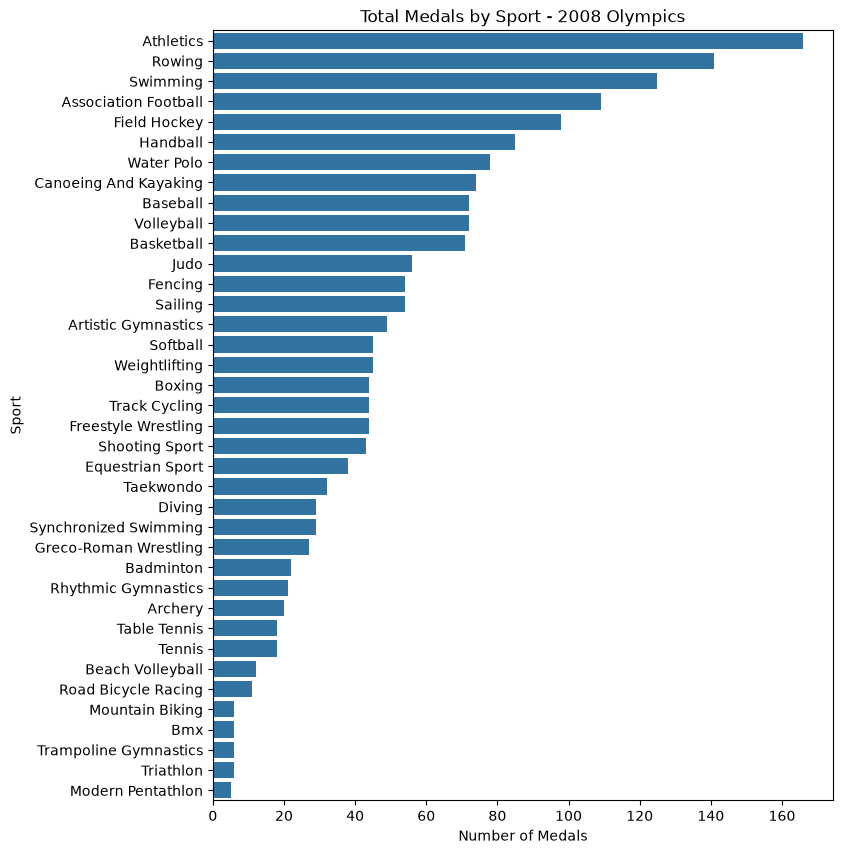

In [46]:
plt.figure(figsize=(8,10))
sns.countplot(data=df_long, y="sport", order=df_long["sport"].value_counts().index)
plt.xlabel("Number of Medals")
plt.title("Total Medals by Sport - 2008 Olympics")
plt.ylabel("Sport") 
plt.show()

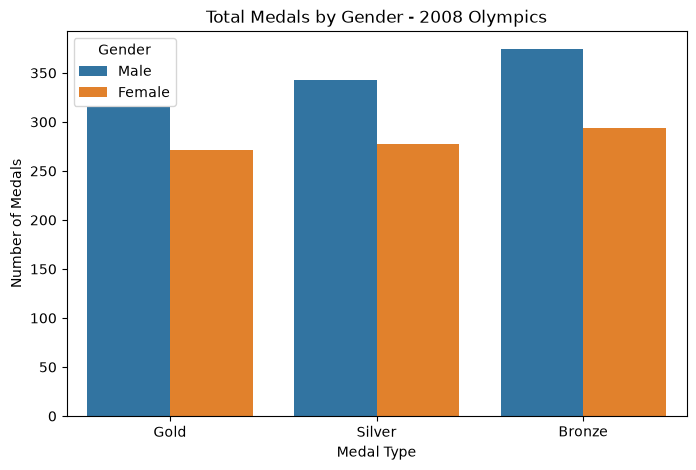

In [55]:
plt.figure(figsize=(8,5))
sns.countplot(data=df_long, x="medal", hue="gender", order=["Gold", "Silver", "Bronze"])
plt.title("Total Medals by Gender - 2008 Olympics")
plt.xlabel("Medal Type")
plt.ylabel("Number of Medals")
plt.legend(title="Gender")
plt.show()